# FotoApp: procesamiento de imágenes para redes sociales

##Programación Python Avanzada — Proyecto 2, primera parte**

Pruebas de las funciones de `fotoapp.py` sobre fotografías reales.

## 1. Importaciones y fotografías de entrada

In [19]:
import sys
from datetime import datetime
from pathlib import Path

%matplotlib inline
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageFilter

ROOT = Path.cwd() if (Path.cwd() / 'fotoapp2.py').is_file() else Path.cwd() / 'proyecto_2'
sys.path.insert(0, str(ROOT))
from fotoapp3 import publicar_foto, ecualizador, filtros, boceto, mostrar_imagen

In [49]:
FOTOS = {
    'redes': ROOT / 'imagenes' / 'redes.jpeg',        # adaptación a redes sociales
    'oscura': ROOT / 'imagenes' / 'oscura.jpeg',      # contraste: imagen oscura
    'luminosa': ROOT / 'imagenes' / 'luminosa.jpeg',  # contraste: imagen con exceso de luz
    'filtros': ROOT / 'imagenes' / 'filtrar.jpg',    # nueve filtros de Pillow
    'retrato': ROOT / 'imagenes' / 'persona.jpeg',    # bocetos de línea
}

faltantes = [str(ruta) for ruta in FOTOS.values() if not ruta.is_file()]
if faltantes:
    raise FileNotFoundError('Faltan fotografías de entrada: ' + ', '.join(faltantes))

for uso, ruta in FOTOS.items():
    with Image.open(ruta) as foto:
        print(f'{uso:<9} {ruta.name:<14} {foto.width} × {foto.height} px')

SALIDA = ROOT / 'results' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
SALIDA.mkdir(parents=True)

redes     redes.jpeg     678 × 452 px
oscura    oscura.jpeg    504 × 396 px
luminosa  luminosa.jpeg  563 × 452 px
filtros   filtrar.jpg    750 × 562 px
retrato   persona.jpeg   386 × 518 px


In [25]:
def mostrar_paneles(imagenes, titulos, nombre_archivo, columnas=None):
    columnas = columnas or len(imagenes)
    filas = -(-len(imagenes) // columnas)
    figura, ejes = plt.subplots(filas, columnas, figsize=(5 * columnas, 4.5 * filas), squeeze=False)
    for eje in ejes.flat:
        eje.axis('off')
    for eje, imagen, titulo in zip(ejes.flat, imagenes, titulos):
        eje.imshow(imagen, cmap='gray', vmin=0, vmax=255)
        eje.set_title(titulo)
    figura.tight_layout()
    figura.savefig(SALIDA / nombre_archivo, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(figura)

In [13]:
SALIDA = ROOT / 'results' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
SALIDA.mkdir(parents=True)

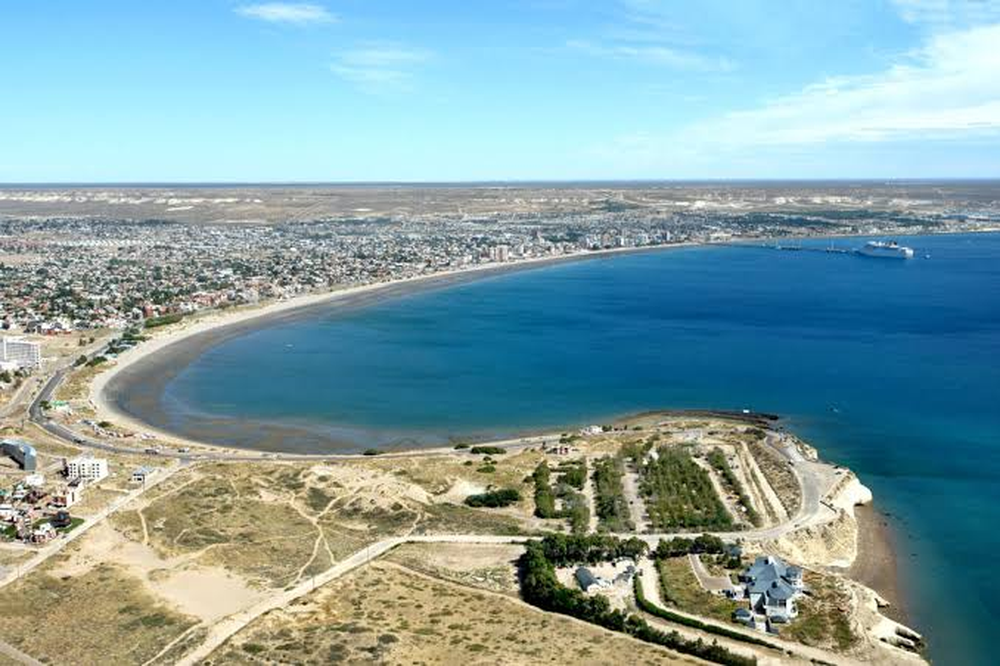

In [14]:
youtube = publicar_foto('https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRgbjBjQBcdwgMWtuA9EVbG8NbC9KWGlk4j-HP3oOVN2w&s=10','Youtube')

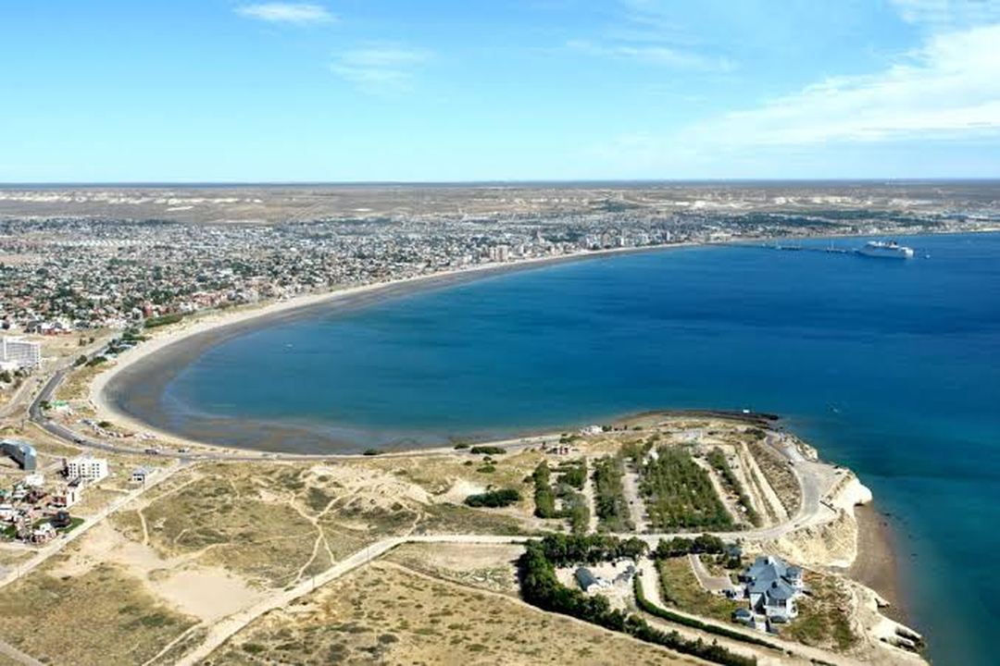

In [7]:
instagram = publicar_foto('https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRgbjBjQBcdwgMWtuA9EVbG8NbC9KWGlk4j-HP3oOVN2w&s=10','Instagram')

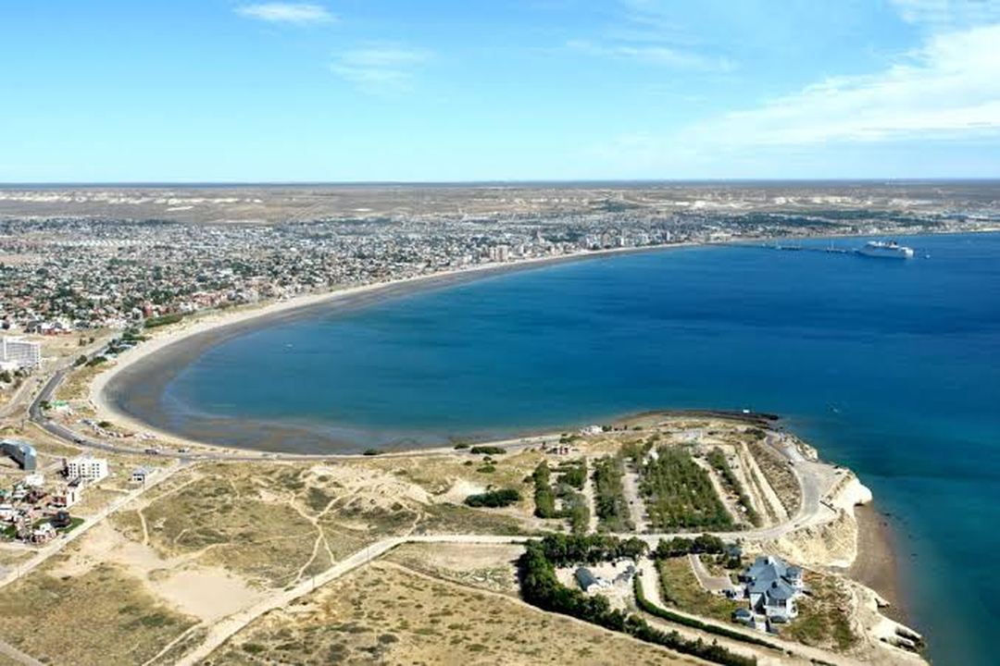

In [8]:
facebook = publicar_foto('https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRgbjBjQBcdwgMWtuA9EVbG8NbC9KWGlk4j-HP3oOVN2w&s=10','Facebook')

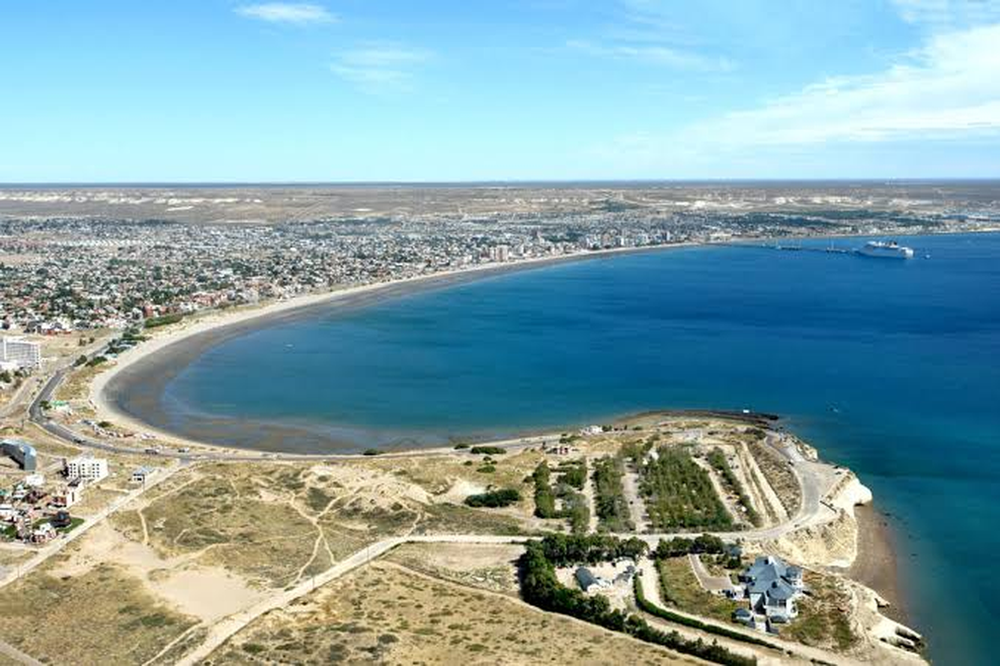

In [9]:
X = publicar_foto('https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcRgbjBjQBcdwgMWtuA9EVbG8NbC9KWGlk4j-HP3oOVN2w&s=10','X')

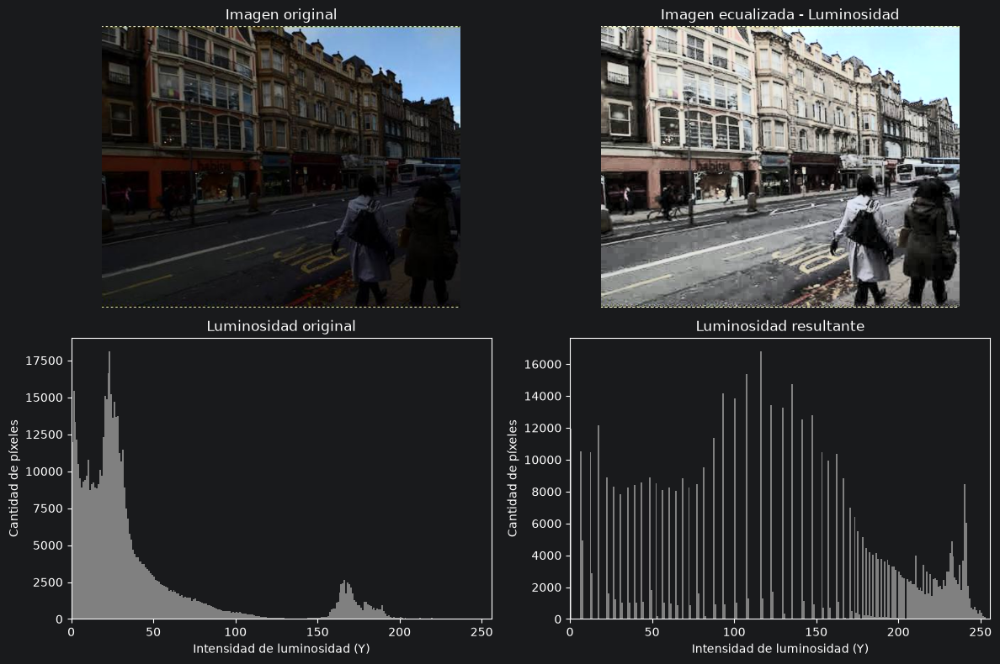

In [34]:
imagen_oscura = publicar_foto('https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcT1QDnMVrQ_qeOqcU38OBHwgZdnx6yYK48ZdwlAHmfhbQ&s=10', 'X')
imagen_ecualizada1 = ecualizador(imagen_oscura)

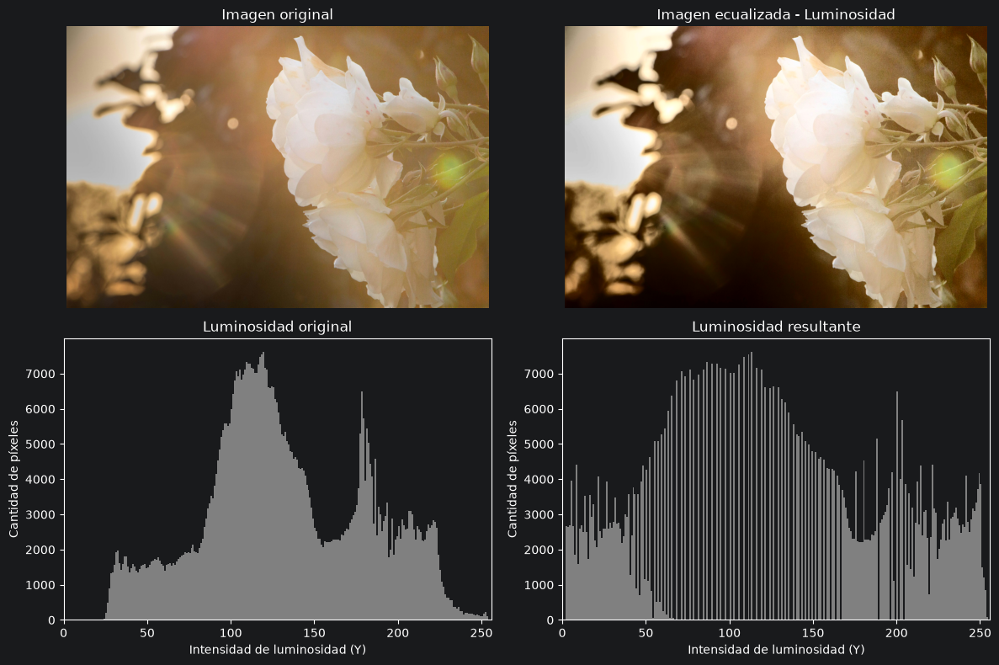

In [35]:
imagen_luminosa = publicar_foto('https://images.unsplash.com/photo-1549449390-012d06a7d7c4?fm=jpg&q=60&w=3000&auto=format&fit=crop&ixlib=rb-4.1.0&ixid=NHwxMjA3fDA%3D', 'X')
imagen_ecualizada2 = ecualizador(imagen_luminosa)

In [32]:
def experimento_rgb(caso, entrada, ecualizada_y):
    canales = [Image.fromarray(cv2.equalizeHist(np.asarray(canal))) for canal in entrada.split()]
    ecualizada_rgb = entrada.copy()
    ecualizada_rgb.paste(Image.merge('RGB', canales))

    mostrar_paneles([entrada, ecualizada_y, ecualizada_rgb],
                    [f'Original ({caso})', 'Ecualización de Y', 'Ecualización de R, G y B'],
                    f'experimento_rgb_{caso}.png')

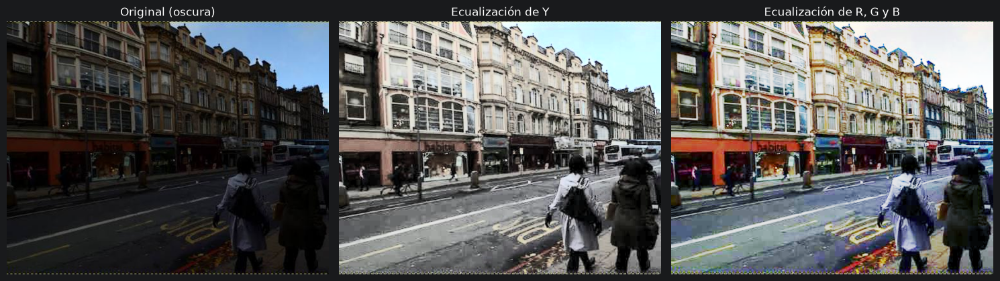

In [36]:
experimento_rgb('oscura',imagen_oscura, imagen_ecualizada1)

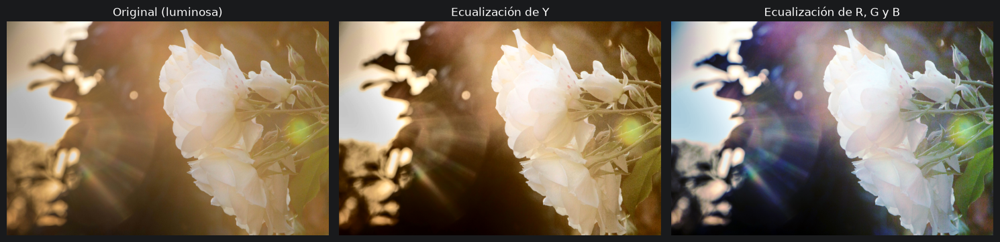

In [37]:
experimento_rgb('luminosa',imagen_luminosa, imagen_ecualizada2)

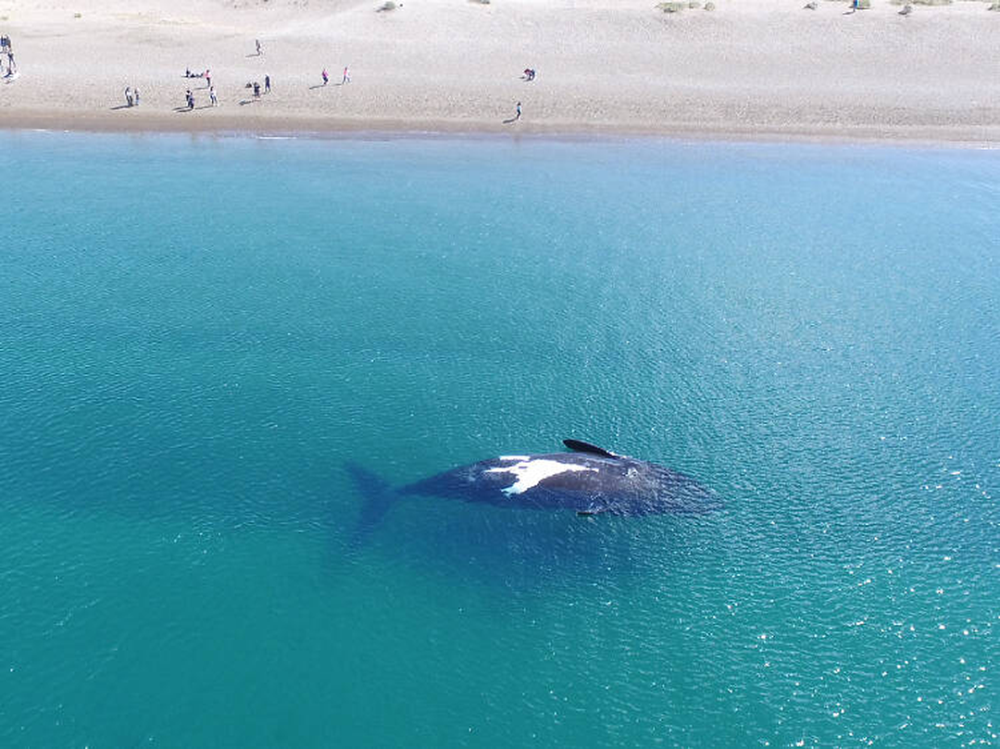

In [38]:
entrada_filtros = publicar_foto(str(FOTOS['filtros']), 'Instagram')
copia_filtros = np.asarray(entrada_filtros).copy()
resultados_filtros = {}


def aplicar_filtro(nombre):
    archivo = SALIDA / f'filtro_{nombre.lower().replace(" ", "_")}.png'
    resultado = filtros(entrada_filtros, nombre, archivo_salida=str(archivo))
    if not np.array_equal(np.asarray(entrada_filtros), copia_filtros):
        raise ValueError('Los filtros se acumularon sobre la entrada')
    resultados_filtros[nombre] = resultado

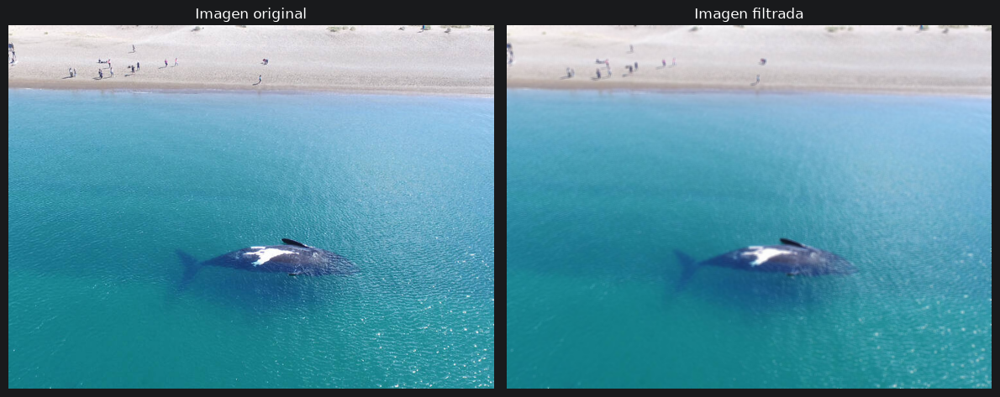

In [39]:
aplicar_filtro('Blur')

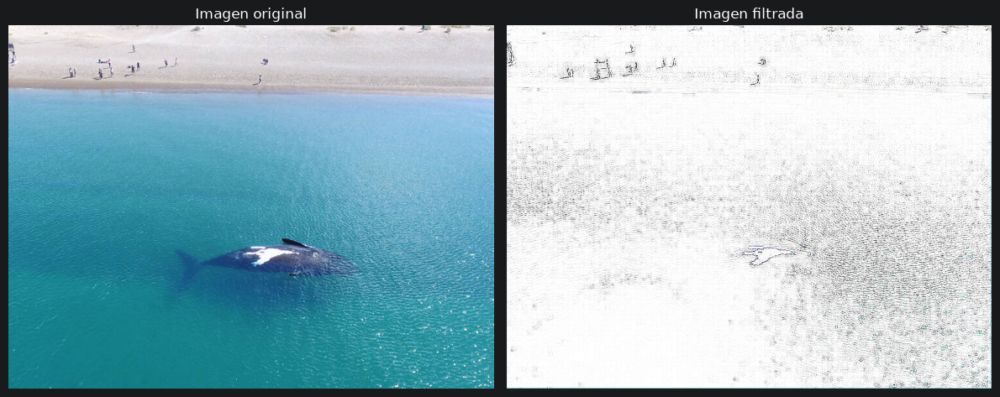

In [40]:
aplicar_filtro('Contour')

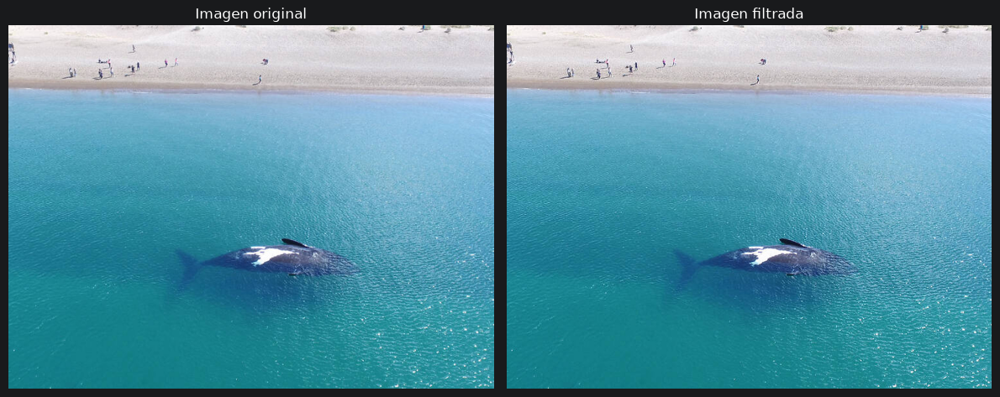

In [41]:
aplicar_filtro('Detail')

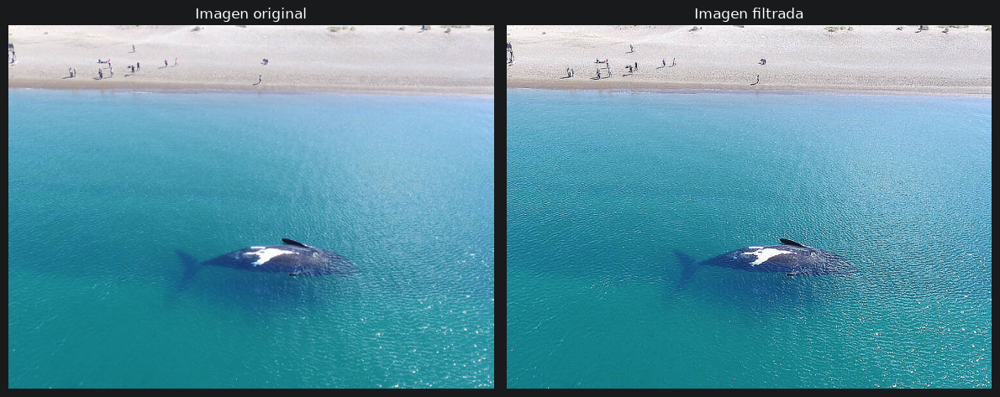

In [42]:
aplicar_filtro('Edge Enhance')

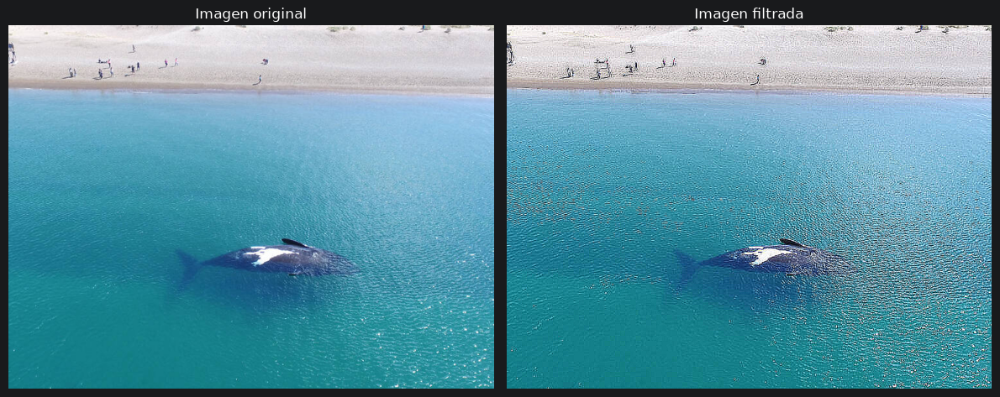

In [43]:
aplicar_filtro('Edge Enhance More')

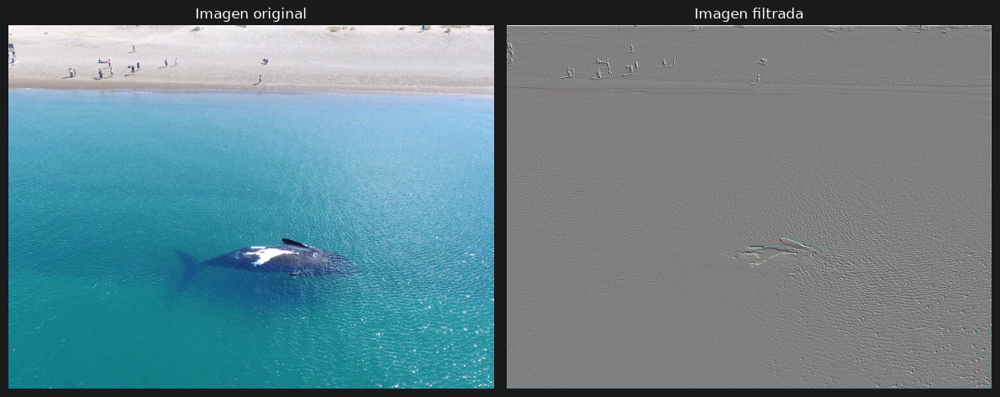

In [44]:
aplicar_filtro('Emboss')

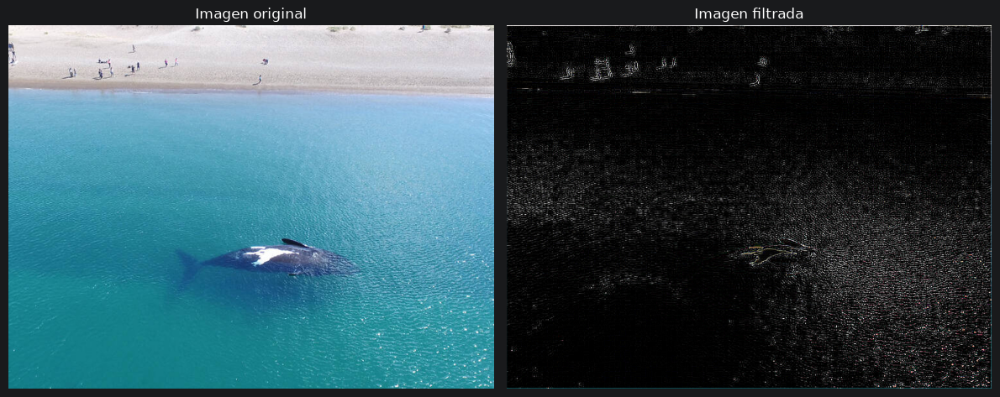

In [45]:
aplicar_filtro('Find Edges')

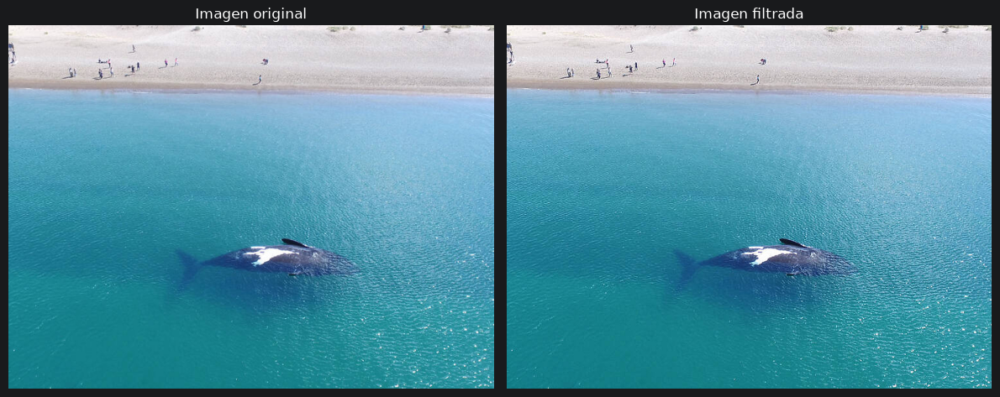

In [46]:
aplicar_filtro('Sharpen')

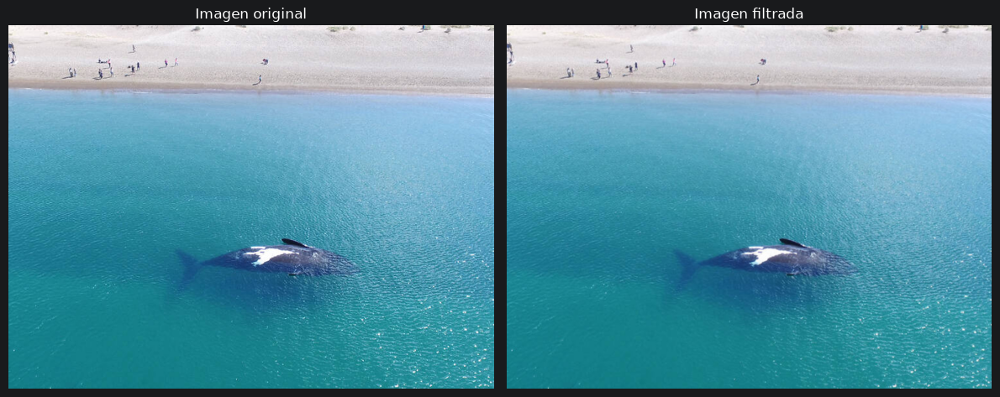

In [47]:
aplicar_filtro('Smooth')

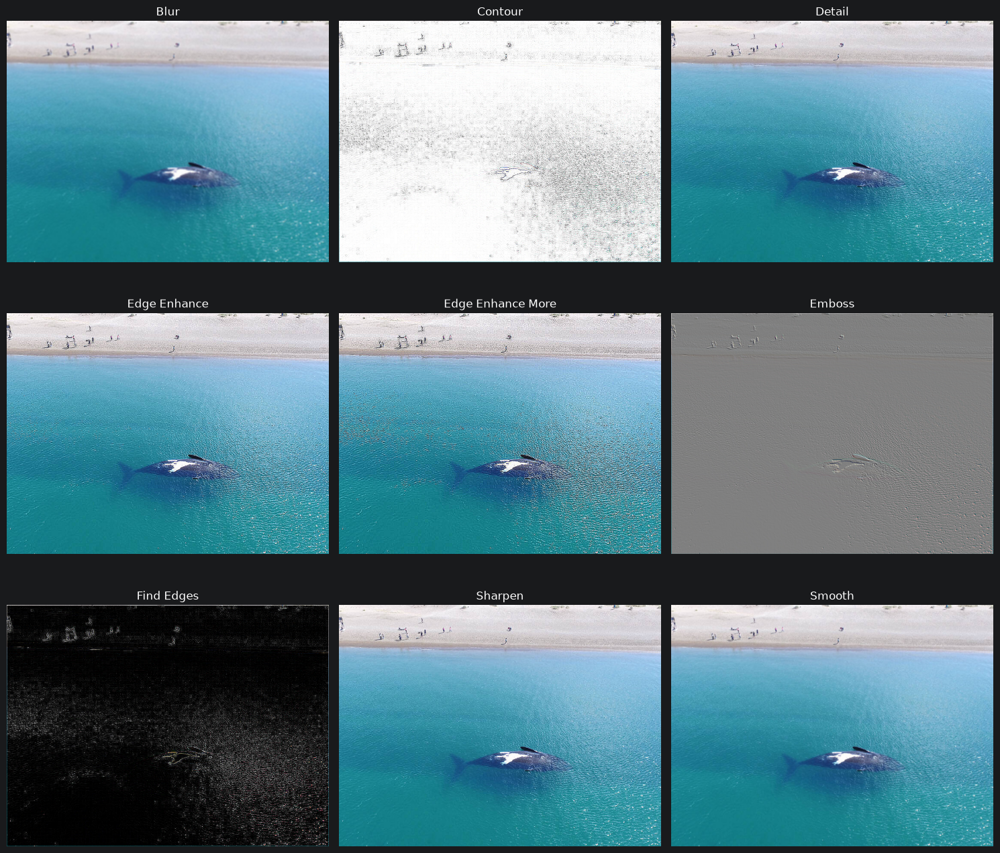

In [48]:
mostrar_paneles(list(resultados_filtros.values()), list(resultados_filtros), 'filtros_vista_conjunta.png', columnas=3)

## 5. Boceto de línea a partir de un retrato

Se comparan Sobel y Canny sobre el mismo retrato, con dos configuraciones cada uno. Antes se aplica un desenfoque leve para reducir el ruido, y el resultado se invierte para obtener líneas negras sobre fondo blanco.

El porcentaje de líneas negras permite comparar configuraciones, no medir la calidad del boceto.

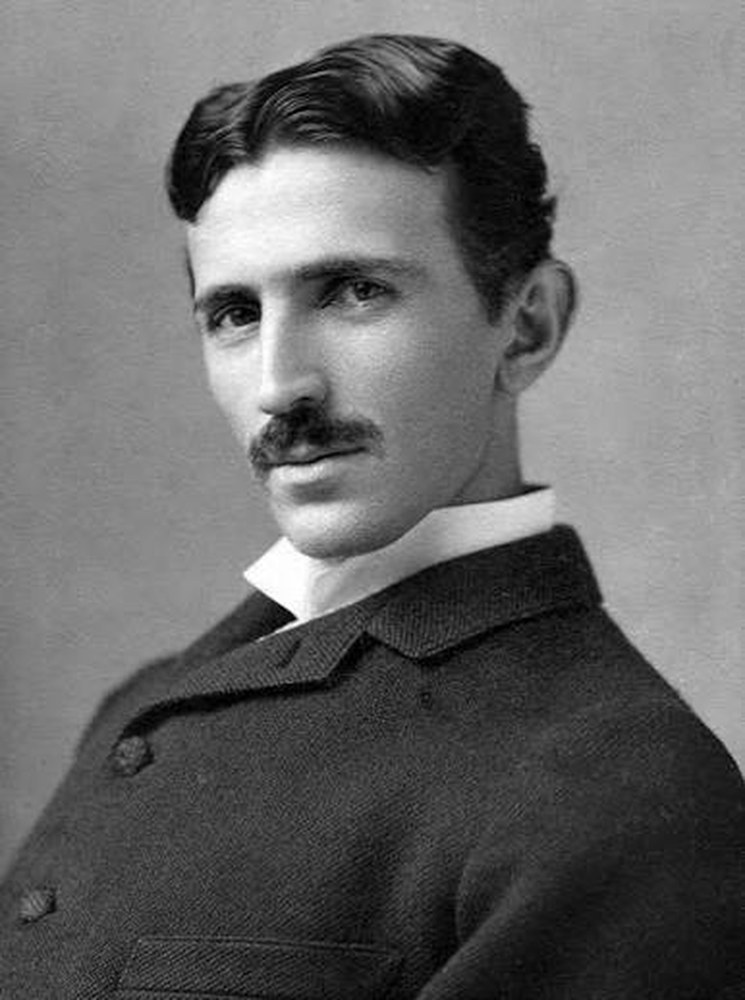

In [50]:
RADIO_SUAVIZADO = 1
retrato = publicar_foto(str(FOTOS['retrato']), 'Instagram')
retrato_suavizado = retrato.copy()
bocetos = {}
titulos_bocetos = {}

def generar_boceto(etiqueta, metodo, umbral=0, kernel=3, umbral1=50, umbral2=150):
    archivo = SALIDA / f'boceto_{etiqueta.lower().replace(" ", "_")}.png'
    resultado = boceto(retrato_suavizado, metodo, True, umbral, kernel, umbral1, umbral2, archivo_salida=str(archivo))
    if metodo == 'Canny':
        titulo = f'Canny, umbrales {umbral1}/{umbral2}'
    else:
        titulo = f'{metodo}, umbral {umbral}'
    bocetos[etiqueta] = resultado
    titulos_bocetos[etiqueta] = titulo

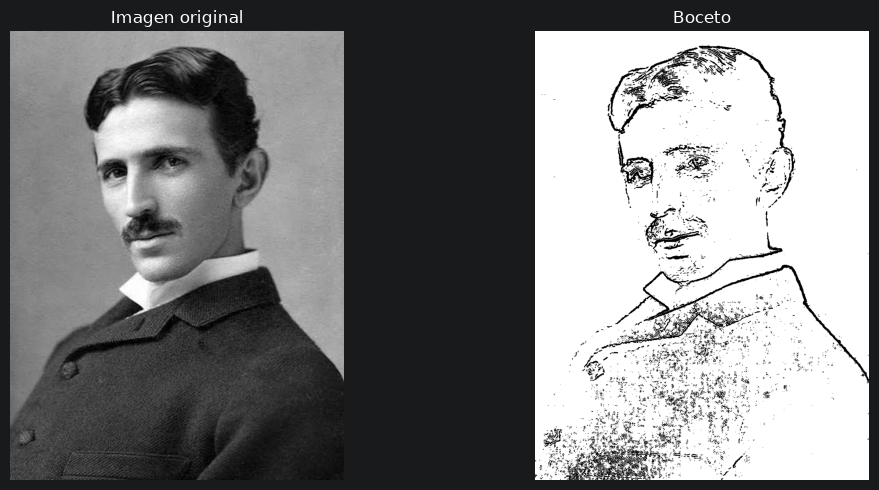

In [51]:
generar_boceto('Sobel A', 'Sobel', umbral=80)

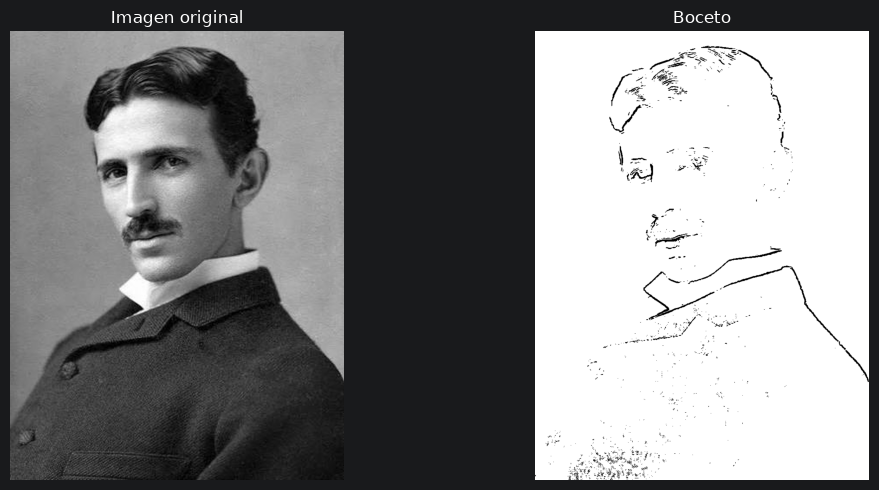

In [52]:
generar_boceto('Sobel B', 'Sobel', umbral=140)

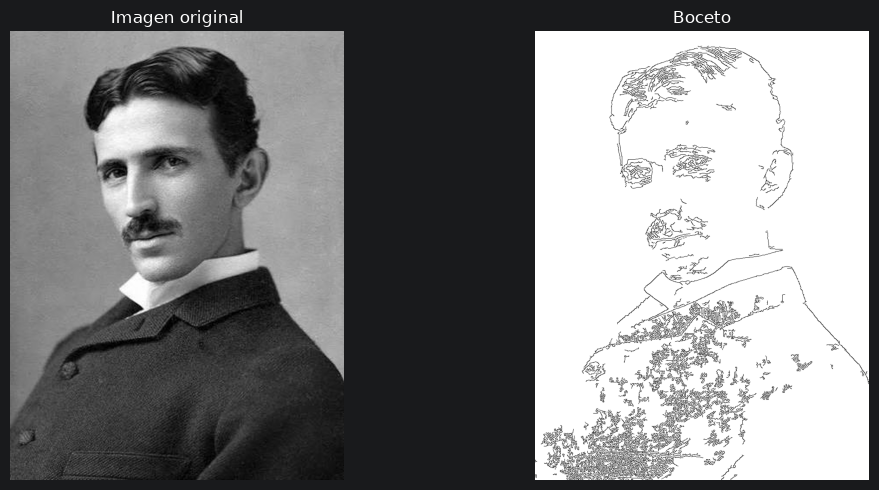

In [53]:
generar_boceto('Canny A', 'Canny', umbral1=50, umbral2=150)

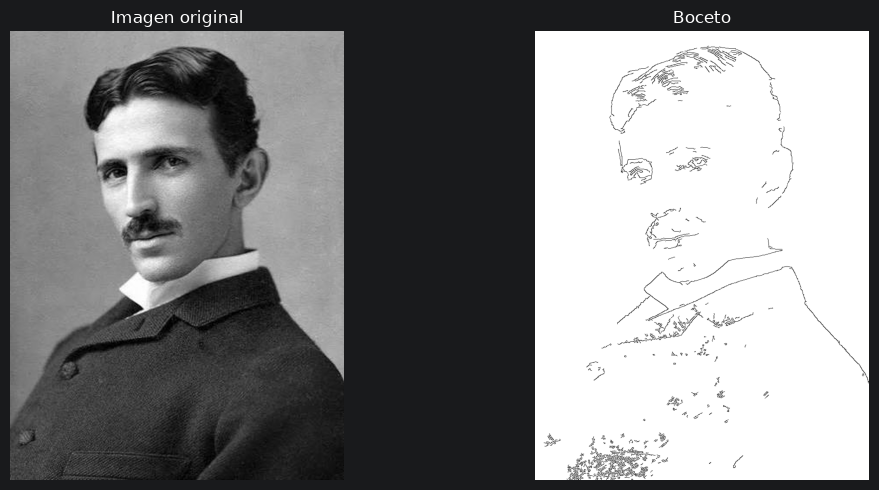

In [54]:
generar_boceto('Canny B', 'Canny', umbral1=100, umbral2=200)

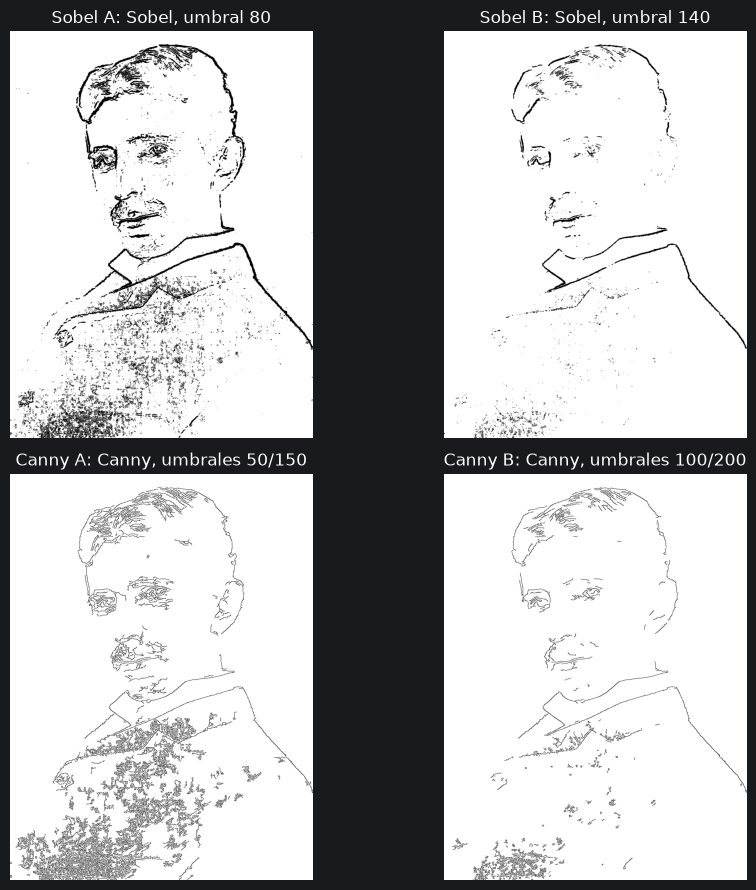

In [55]:
mostrar_paneles(list(bocetos.values()),
                [f'{etiqueta}: {titulo}' for etiqueta, titulo in titulos_bocetos.items()],
                'bocetos_configuraciones.png', columnas=2)

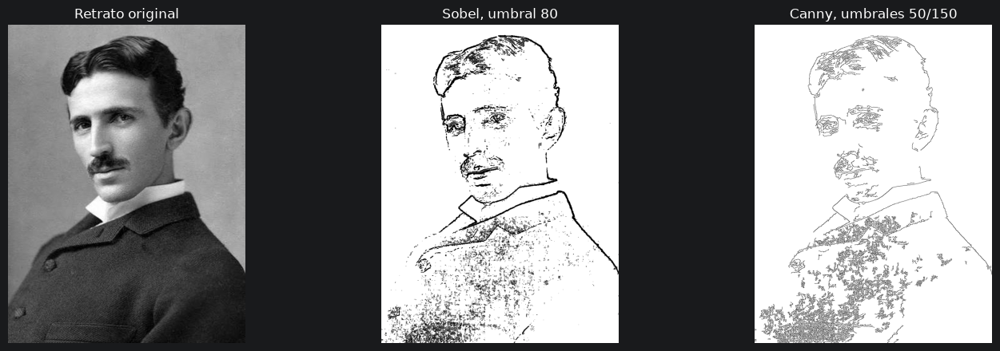

In [56]:
mostrar_paneles([retrato, bocetos['Sobel A'], bocetos['Canny A']],
                ['Retrato original', titulos_bocetos['Sobel A'], titulos_bocetos['Canny A']],
                'bocetos_comparacion_final.png')

## 6. Validación de entradas

Las funciones rechazan las entradas inválidas con excepciones, que el menú captura para que el usuario pueda continuar.

In [59]:
casos_invalidos = [
    ('Red no admitida', lambda: publicar_foto(str(FOTOS['redes']), 'MySpace'), ValueError),
    ('Archivo inexistente', lambda: publicar_foto(str(ROOT / 'imagenes' / 'no_existe.jpg'), 'Instagram'), FileNotFoundError),
    ('Filtro inexistente', lambda: filtros(entrada_filtros, 'Sepia'), ValueError),
    ('Umbrales de Canny invertidos', lambda: boceto(retrato, 'Canny', False, 0, 3, 200, 100), ValueError),
]

for descripcion, operacion, excepcion in casos_invalidos:
    try:
        operacion()
    except excepcion as error:
        print(f'{descripcion}: {type(error).__name__} — {error}')
    else:
        raise ValueError(f'No se rechazó: {descripcion}')

Red no admitida: ValueError — No se puede subir la imagen a MYSPACE
Archivo inexistente: FileNotFoundError — [Errno 2] No such file or directory: 'C:\\Users\\alvar\\OneDrive\\Documents\\Python\\imagenes\\no_existe.jpg'
Filtro inexistente: ValueError — No se puede aplicar el filtro Sepia
Umbrales de Canny invertidos: ValueError — Canny requiere 0 <= umbral1 < umbral2 <= 255


## 7. Conclusiones

**Adaptación.** Una única escala para ambos ejes conserva la proporción, y completar con márgenes evita recortar el encuadre. El costo son las franjas grises cuando la relación de aspecto de la foto difiere de la de la red. Registrar el área de la foto permite excluir esas franjas de todas las operaciones posteriores sin depender del color del fondo, que podría confundirse con zonas grises de la propia imagen.

**Contraste.** La ecualización redistribuye los niveles de luminosidad para ocupar todo el rango. El aumento del desvío de Y indica una distribución más amplia, no una imagen necesariamente mejor: en las zonas uniformes también puede aumentar el ruido. Los píxeles que ya estaban en 0 o en 255 no recuperan el detalle perdido, y la ecualización tampoco lo reconstruye. Ecualizar solo Y conserva los colores mejor que ecualizar R, G y B por separado, ya que este último procedimiento modifica la relación entre canales.

**Filtros.** Los filtros de suavizado y de realce actúan sobre la textura y la nitidez, pero conservan la fotografía reconocible. Contour, Find Edges y Emboss la transforman en una representación de bordes o de relieve. La magnitud del cambio que produce un filtro no indica su calidad: la elección depende del uso que se le quiera dar a la imagen.

**Bocetos.** En Sobel, el umbral regula directamente la cantidad de líneas. Canny tiende a producir bordes más finos y continuos, a cambio de dos umbrales que hay que ajustar en conjunto. Las densidades impresas permiten comparar configuraciones, pero la valoración del parecido requiere observar las figuras.

**Alcance.** Las observaciones visuales dependen de las fotografías de entrada y deben hacerse sobre las figuras de cada ejecución. Este notebook no realiza descargas: la carga desde una URL está cubierta por las pruebas automatizadas de `test_fotoapp.py`.